In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X = np.random.rand(100, 1) * 10
y = 3 * X[:, 0] + 5 + np.random.randn(100)

print("Dataset created successfully!")
print("Number of samples:", len(X))


Dataset created successfully!
Number of samples: 100


In [2]:
def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)
def gradients(X, y, w, b):
    n = len(y)
    y_pred = w * X[:, 0] + b

    dw = (-2 / n) * np.sum(X[:, 0] * (y - y_pred))
    db = (-2 / n) * np.sum(y - y_pred)

    return dw, db


In [3]:

def gradient_descent(X, y, learning_rate, iterations):
    w = 0
    b = 0
    losses = []

    for i in range(iterations):
        y_pred = w * X[:, 0] + b

        loss = mse(y, y_pred)
        losses.append(loss)

        dw, db = gradients(X, y, w, b)

        w = w - learning_rate * dw
        b = b - learning_rate * db

    return w, b, losses


w, b, losses = gradient_descent(X, y, 0.01, 1000)

print("Weight:", w)
print("Bias:", b)
print("Final MSE:", mse(y, w * X[:, 0] + b))


Weight: 2.956767923204079
Bias: 5.1972348935062085
Final MSE: 0.8066751324927918


In [4]:

model = LinearRegression()
model.fit(X, y)

our_predictions = w * X[:, 0] + b
sklearn_predictions = model.predict(X)

print("Our Gradient Descent:")
print("Weight:", w)
print("Bias:", b)
print("MSE:", mse(y, our_predictions))

print("\nScikit-learn:")
print("Weight:", model.coef_[0])
print("Bias:", model.intercept_)
print("MSE:", mean_squared_error(y, sklearn_predictions))


Our Gradient Descent:
Weight: 2.956767923204079
Bias: 5.1972348935062085
MSE: 0.8066751324927918

Scikit-learn:
Weight: 2.954022677287696
Bias: 5.215096157546753
MSE: 0.8065845639670531


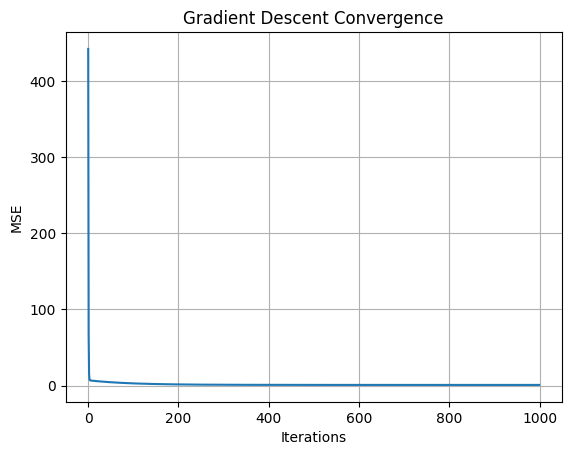

In [5]:

plt.plot(losses)

plt.xlabel("Iterations")
plt.ylabel("MSE")
plt.title("Gradient Descent Convergence")
plt.grid(True)
plt.show()


Learning rate: 0.001
Final MSE: 2.83352248979021

Learning rate: 0.01
Final MSE: 0.8066761456463122

Learning rate: 0.02
Final MSE: 0.8065845652503865



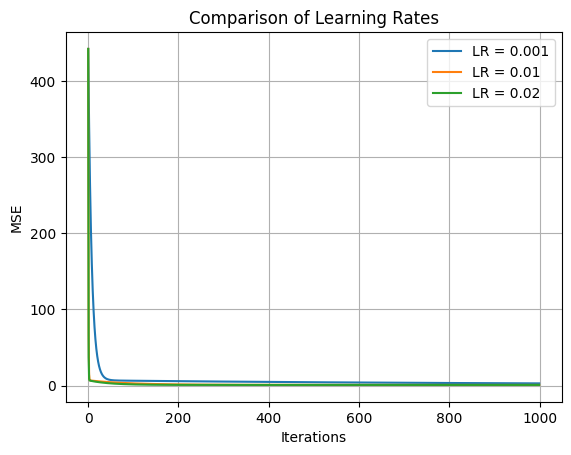

In [6]:

learning_rates = [0.001, 0.01, 0.02]

for lr in learning_rates:
    w_new, b_new, losses_new = gradient_descent(X, y, lr, 1000)

    plt.plot(losses_new, label=f"LR = {lr}")

    print("Learning rate:", lr)
    print("Final MSE:", losses_new[-1])
    print()

plt.xlabel("Iterations")
plt.ylabel("MSE")
plt.title("Comparison of Learning Rates")
plt.legend()
plt.grid(True)
plt.show()


## Conclusion

In this assignment, I implemented linear regression using gradient descent with NumPy.

First, I created the Mean Squared Error (MSE) function and calculated the gradients manually.

Next, I implemented gradient descent to update the weight and bias over 1,000 iterations.

I compared my implementation with scikit-learn's LinearRegression model. Both models produced similar coefficients and MSE values.

Finally, I tested three learning rates: 0.001, 0.01, and 0.02. The convergence graphs showed that the learning rate affects how quickly the model reduces its error.

Overall, gradient descent successfully minimized the loss function, and the results were close to those obtained using scikit-learn.